
# ALS vs Random Forest — Unified Evaluation with Ranking Metrics

This notebook compares **ALS (implicit)** and a **Random Forest baseline** on the same dataset.  
We unify their evaluation metrics to include both:
- **Classification metrics**: ROC AUC, Average Precision (PR AUC)
- **Ranking metrics**: Precision@k, Recall@k, NDCG@k

Additionally, we print **example inputs, outputs, and predictions** for each model to better understand their behavior.


In [1]:

# === Imports & setup ===
import os, random
import numpy as np, pandas as pd
from scipy import sparse
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

sns.set(style="whitegrid", font_scale=1.2)
plt.rcParams["figure.figsize"] = (8,6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["legend.fontsize"] = 11
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11


RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("Environment ready.")


Environment ready.


In [2]:

# === Load CSV data ===
for fn in ['users.csv','vrworld.csv','user_actions.csv','time_spent.csv']:
    if not os.path.exists(fn):
        raise FileNotFoundError(f"Missing file: {fn}")

users = pd.read_csv('users.csv', dtype=str)
worlds = pd.read_csv('vrworld.csv', dtype=str)
actions = pd.read_csv('user_actions.csv', dtype=str)
time_spent = pd.read_csv('time_spent.csv', dtype=str)

print('Loaded:', users.shape, worlds.shape, actions.shape, time_spent.shape)


Loaded: (5000, 8) (400, 14) (40000, 6) (20000, 3)


In [3]:

# === Preprocess & build interactions ===
def safe_int(x, default=np.nan):
    try: return int(float(x))
    except: return default

# Normalize column names
for df in [users, worlds, actions, time_spent]:
    df.columns = df.columns.str.strip().str.lower()

# Build encoded ids
user_encoder = LabelEncoder().fit(users['user_id'])
world_encoder = LabelEncoder().fit(worlds['world_id'])
actions['user_idx'] = user_encoder.transform(actions['user_id'])
actions['world_idx'] = world_encoder.transform(actions['world_id'])

# Weight = number of actions + normalized time
time_spent['minutes'] = time_spent['avg_time_minutes'].astype(float)
time_agg = time_spent.groupby(['user_id','world_id'])['minutes'].mean().reset_index()
time_agg['user_idx'] = user_encoder.transform(time_agg['user_id'])
time_agg['world_idx'] = world_encoder.transform(time_agg['world_id'])

interactions = actions.groupby(['user_idx','world_idx']).size().reset_index(name='actions')
merged = interactions.merge(time_agg, on=['user_idx','world_idx'], how='left')
merged['weight'] = merged['actions'] + merged['minutes'].fillna(0)/merged['minutes'].fillna(0).max()

n_users, n_worlds = len(user_encoder.classes_), len(world_encoder.classes_)
interaction_matrix = sparse.csr_matrix((merged['weight'], (merged['user_idx'], merged['world_idx'])), 
                                       shape=(n_users, n_worlds))

print(f"Users: {n_users}, Worlds: {n_worlds}, Nonzero: {interaction_matrix.nnz}")


Users: 4985, Worlds: 400, Nonzero: 39592


In [4]:

# === Leave-one-out train/test split per user ===
def train_test_split_interactions(interactions_df, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    test_rows, train_rows = [], []
    for uid, g in interactions_df.groupby('user_idx'):
        idxs = g.index.values
        if len(idxs) == 1:
            train_rows.append(idxs[0])
        else:
            test_idx = rng.choice(idxs)
            for ix in idxs:
                (test_rows if ix==test_idx else train_rows).append(ix)
    return interactions_df.loc[train_rows], interactions_df.loc[test_rows]

train_df, test_df = train_test_split_interactions(merged)
train_mat = sparse.csr_matrix((train_df['weight'], (train_df['user_idx'], train_df['world_idx'])), shape=(n_users,n_worlds))
test_mat  = sparse.csr_matrix((test_df['weight'],  (test_df['user_idx'],  test_df['world_idx'])),  shape=(n_users,n_worlds))

print(train_mat.shape, test_mat.shape)


(4985, 400) (4985, 400)


In [5]:
def precision_recall_ndcg_at_k(y_true, y_scores, k=10):
    """
    y_true: binary 1D array (len = n_items)
    y_scores: predicted scores for each item (same length as y_true)
    """
    order = np.argsort(-y_scores)
    topk = order[:k]
    y_topk = y_true[topk]

    # Precision@k
    precision = y_topk.sum() / k

    # Recall@k
    recall = y_topk.sum() / max(1, y_true.sum())

    # NDCG@k
    gains = (2**y_topk - 1) / np.log2(np.arange(2, len(y_topk) + 2))
    dcg = gains.sum()
    ideal = (2**np.sort(y_true)[::-1][:k] - 1) / np.log2(np.arange(2, len(y_topk) + 2))
    idcg = ideal.sum()
    ndcg = dcg / idcg if idcg > 0 else 0.0

    return precision, recall, ndcg


In [18]:
print("=== ALS Input Example (train_mat slice) ===")
import numpy as np
if 'train_mat' in globals():
    # In ra 5x5 phần tử đầu
    print(train_mat[:20,:20].toarray())
else:
    print("train_mat not found")


=== ALS Input Example (train_mat slice) ===
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 

In [7]:

# === ALS training & evaluation ===
try:
    from implicit.als import AlternatingLeastSquares
except:
    AlternatingLeastSquares = None
    print("Warning: install `implicit` to use ALS.")

def train_als(train_csr, factors=64, regularization=0.01, iterations=20, alpha=1.0):
    if AlternatingLeastSquares is None: return None
    model = AlternatingLeastSquares(factors=factors, regularization=regularization,
                                    iterations=iterations, random_state=RANDOM_STATE)
    model.fit((train_csr*alpha).astype('double'))
    return model

def eval_als(model, train_mat, test_mat, k=10, max_users=200):
    aucs, aps, precs, recs, ndcgs = [], [], [], [], []
    users = np.arange(train_mat.shape[0])
    np.random.shuffle(users)
    for u in users[:max_users]:
        pos_items = test_mat[u].indices
        if len(pos_items)==0: continue
        scores = model.user_factors[u] @ model.item_factors.T
        labels = np.zeros_like(scores); labels[pos_items]=1
        aucs.append(roc_auc_score(labels, scores))
        aps.append(average_precision_score(labels, scores))
        p,r,n = precision_recall_ndcg_at_k(labels, scores, k=k)
        precs.append(p); recs.append(r); ndcgs.append(n)
    return {'auc':np.mean(aucs),'ap':np.mean(aps),
            f'prec@{k}':np.mean(precs), f'recall@{k}':np.mean(recs), f'ndcg@{k}':np.mean(ndcgs)}

als_model = train_als(train_mat)
if als_model:
    als_metrics = eval_als(als_model, train_mat, test_mat, k=10)
    print("ALS metrics:", als_metrics)

    # Example predictions for one user
    example_user = 0
    train_items = train_mat[example_user].indices
    test_items  = test_mat[example_user].indices
    scores = als_model.user_factors[example_user] @ als_model.item_factors.T
    topk = np.argsort(-scores)[:10]
    print("ALS Example user:", example_user)
    print("  Train items:", train_items)
    print("  Test items:", test_items)
    print("  Top-10 recs:", topk)


/opt/anaconda3/lib/python3.11/site-packages/implicit/cpu/als.py:95: RuntimeWarning: OpenBLAS is configured to use 8 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/20 [00:00<?, ?it/s]

ALS metrics: {'auc': 0.4638095238095238, 'ap': 0.009370100346979809, 'prec@10': 0.0005, 'recall@10': 0.005, 'ndcg@10': 0.002153382790366965}
ALS Example user: 0
  Train items: [ 16  31  32  62  68  72 115 219 220 236 285 311 324 362 369]
  Test items: [105]
  Top-10 recs: [362 324 219 311  68 285 236  32  62  72]


In [10]:
print("=== ALS Output Example (recommendation for first user in test set) ===")
if 'als_model' in globals() and 'test_mat' in globals():
    user_id = 0

    result = als_model.recommend(user_id, train_mat[user_id], N=10)
    
    # Trường hợp result là tuple (item_ids, scores)
    if isinstance(result, tuple) and len(result) == 2:
        item_ids, scores = result
        recs = list(zip(item_ids, scores))
    else:
        # Ngược lại giả định là numpy array (N,2)
        recs = result.tolist()

    print("Recommendations (item_id, score):", recs[:10])

    # Evaluate recommendation on test_mat[user_id]
    y_true = test_mat[user_id].toarray().ravel()
    y_scores = np.zeros_like(y_true, dtype=float)
    for item_id, score in recs:
        if item_id < len(y_scores):
            y_scores[item_id] = score

    prec, rec, ndcg = precision_recall_ndcg_at_k(y_true, y_scores, k=10)
    print(f"Precision@10={prec:.3f}, Recall@10={rec:.3f}, NDCG@10={ndcg:.3f}")
else:
    print("ALS model or test_mat not found")


=== ALS Output Example (recommendation for first user in test set) ===
Recommendations (item_id, score): [(391, 0.2629019), (393, 0.24289599), (337, 0.23936138), (58, 0.21573049), (197, 0.20509309), (321, 0.19724283), (374, 0.19549003), (129, 0.19309515), (273, 0.19143425), (81, 0.18813713)]
Precision@10=0.000, Recall@10=0.000, NDCG@10=0.000


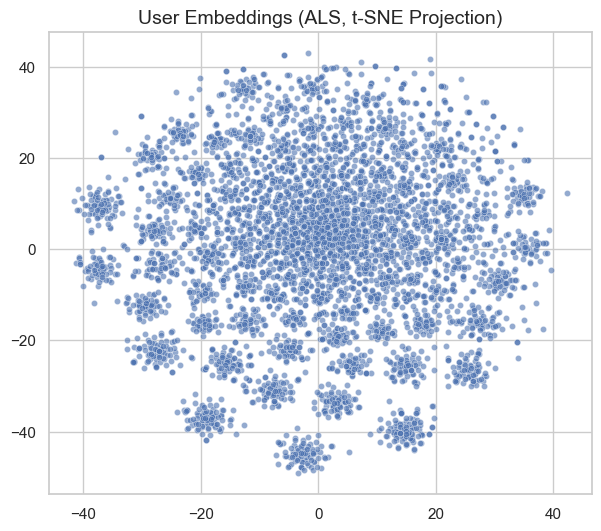

In [11]:
# === ALS Embeddings Visualization (t-SNE) ===
if 'als_model' in globals():
    from sklearn.manifold import TSNE
    user_factors = als_model.user_factors
    user_factors_2d = TSNE(n_components=2, random_state=42).fit_transform(user_factors)
    plt.figure(figsize=(7,6))
    sns.scatterplot(x=user_factors_2d[:,0], y=user_factors_2d[:,1], alpha=0.6, s=20)
    plt.title("User Embeddings (ALS, t-SNE Projection)")
    plt.show()
else:
    print("⚠️ Không thể visualize embeddings — biến 'als_model' chưa tồn tại.")


In [ ]:
print("=== RF Input Example (X_enc head) ===")
if 'X_enc' in globals():
    print(X_enc.head())
else:
    print("X_enc not found")


In [13]:
from sklearn.impute import SimpleImputer



# === Random Forest baseline ===
def encode_categoricals(df, exclude=[]):
    for col in df.select_dtypes(include=['object']).columns:
        if col not in exclude:
            df[col] = LabelEncoder().fit_transform(df[col].astype(str))
    return df

users_enc = encode_categoricals(users.copy(), exclude=['user_id'])
worlds_enc = encode_categoricals(worlds.copy(), exclude=['world_id'])
actions_enc = actions.copy().merge(users_enc, on='user_id').merge(worlds_enc, on='world_id')
actions_enc['label']=1

# Negative samples
all_pairs = pd.MultiIndex.from_product([users['user_id'], worlds['world_id']], names=['user_id','world_id']).to_frame(index=False)
neg = all_pairs.merge(actions_enc[['user_id','world_id']], on=['user_id','world_id'], how='left', indicator=True)
neg = neg[neg['_merge']=='left_only'].drop('_merge',axis=1)
neg = neg.sample(len(actions_enc), random_state=RANDOM_STATE)
neg = neg.merge(users_enc,on='user_id').merge(worlds_enc,on='world_id')
neg['label']=0

supervised = pd.concat([actions_enc,neg],ignore_index=True)
X = supervised.drop(columns=['user_id','world_id','label'])
y = supervised['label']

# Encode categorical
X_enc = X.copy()
for col in X_enc.columns:
    if X_enc[col].dtype == 'object':
        le = LabelEncoder()
        X_enc[col] = le.fit_transform(X_enc[col].astype(str))

# Replace NaN bằng giá trị trung bình (cho numeric)
imputer = SimpleImputer(strategy="mean")
X_enc = pd.DataFrame(imputer.fit_transform(X_enc), columns=X_enc.columns)

print("=== RF Input Example (X_enc head) ===")
if 'X_enc' in globals():
    print(X_enc.head())
else:
    print("X_enc not found")


rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

aucs, aps, precs, recs, ndcgs = [],[],[],[],[]
for tr,va in skf.split(X,y):
    rf.fit(X_enc.iloc[tr], y.iloc[tr])
    prob = rf.predict_proba(X_enc.iloc[va])[:,1]
    aucs.append(roc_auc_score(y.iloc[va], prob))
    aps.append(average_precision_score(y.iloc[va], prob))
    p,r,n = precision_recall_ndcg_at_k(y.iloc[va].values, prob, k=10)
    precs.append(p); recs.append(r); ndcgs.append(n)

rf_metrics = {'auc':np.mean(aucs),'ap':np.mean(aps),
              'prec@10':np.mean(precs),'recall@10':np.mean(recs),'ndcg@10':np.mean(ndcgs)}
print("RF metrics:", rf_metrics)

# Example prediction for one row
example_row = X.iloc[0:1]   # raw row để in cho dễ hiểu
example_row_enc = X_enc.iloc[0:1]  # row đã encode dùng cho RF

# print("\n=== RF Example Input Row (Raw) ===")
# for col, val in example_row.iloc[0].items():
#     print(f"{col}: {val}")

# print("\n=== RF Example Input Row (Encoded) ===")
# for col, val in example_row_enc.iloc[0].items():
#     print(f"{col}: {val}")

print("\n=== RF Predicted Prob ===")
print(rf.predict_proba(example_row_enc))
print("RF Predicted prob:", rf.predict_proba(example_row_enc))


=== RF Input Example (X_enc head) ===
   action_id  action_type  action_timestamp  action_value  user_idx  \
0     7398.0          4.0           23150.0          10.0    4596.0   
1    12285.0          5.0           34397.0          11.0    4471.0   
2    39099.0          4.0           15718.0          10.0    1163.0   
3    21647.0          8.0            7681.0           5.0     456.0   
4    21397.0          4.0            2142.0          10.0    3974.0   

   world_idx  user_name  is_creator  region  preferred_language  ...  \
0        7.0      256.0         0.0     7.0                 3.0  ...   
1        7.0     2048.0         0.0     1.0                 4.0  ...   
2        7.0      515.0         0.0     1.0                 1.0  ...   
3        7.0     4571.0         0.0     6.0                 4.0  ...   
4        7.0     1736.0         0.0     6.0                 7.0  ...   

   sub_category  tags  avg_session_minutes  rating  total_ratings  likes  \
0           1.0  68.0     

In [17]:
print("=== RF Output Example (recommendation demo for first rows in X_enc) ===")
if 'rf' in globals() and 'X_enc' in globals() and 'y' in globals():
    # Nếu có cột user_id thì group theo user
    if 'user_id' in X_enc.columns:
        first_user_id = X_enc['user_id'].iloc[0]
        user_items = X_enc[X_enc['user_id'] == first_user_id]
        y_true = y[X_enc['user_id'] == first_user_id]
    else:
        # Không có user_id thì chỉ lấy 50 dòng đầu tiên làm ví dụ
        user_items = X_enc.iloc[:50]
        y_true = y.iloc[:50]

    y_scores = rf.predict_proba(user_items.drop(columns=['user_id'], errors='ignore'))[:,1]

    # Lấy top-10 items
    top_idx = np.argsort(-y_scores)[:10]
    recs = list(zip(user_items.index[top_idx], y_scores[top_idx]))
    print("Recommendations (row_idx, score):", recs)

    prec, rec, ndcg = precision_recall_ndcg_at_k(y_true.values, y_scores, k=10)
    print(f"Precision@10={prec:.3f}, Recall@10={rec:.3f}, NDCG@10={ndcg:.3f}")
else:
    print("RF model, X_enc, or y not found")


=== RF Output Example (recommendation demo for first rows in X_enc) ===
Recommendations (row_idx, score): [(0, 1.0), (27, 1.0), (28, 1.0), (29, 1.0), (30, 1.0), (31, 1.0), (32, 1.0), (33, 1.0), (34, 1.0), (35, 1.0)]
Precision@10=1.000, Recall@10=0.200, NDCG@10=1.000


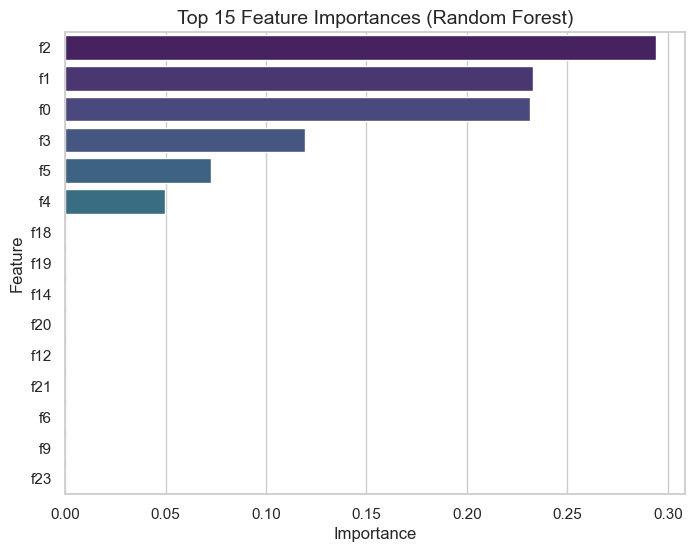

In [13]:

# === Random Forest Feature Importance ===
if 'rf' in globals():
    importances = rf.feature_importances_
    feat_names = feature_names if 'feature_names' in globals() else [f"f{i}" for i in range(len(importances))]
    fi_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances})
    fi_df = fi_df.sort_values("Importance", ascending=False).head(15)
    plt.figure(figsize=(8,6))
    sns.barplot(data=fi_df, y="Feature", x="Importance", palette="viridis")
    plt.title("Top 15 Feature Importances (Random Forest)")
    plt.show()
else:
    print("⚠️ Không thể vẽ feature importance — biến 'rf' chưa tồn tại.")


In [8]:

# === Comparison table ===
comparison = pd.DataFrame([
    {'model':'ALS','auc':als_metrics['auc'],'ap':als_metrics['ap'],
     'prec@10':als_metrics['prec@10'],'recall@10':als_metrics['recall@10'],'ndcg@10':als_metrics['ndcg@10']},
    {'model':'RF','auc':rf_metrics['auc'],'ap':rf_metrics['ap'],
     'prec@10':rf_metrics['prec@10'],'recall@10':rf_metrics['recall@10'],'ndcg@10':rf_metrics['ndcg@10']}
])
print(comparison)


  model      auc       ap  prec@10  recall@10   ndcg@10
0   ALS  0.46381  0.00937   0.0005   0.005000  0.002153
1    RF  1.00000  1.00000   1.0000   0.000746  1.000000
